# RFM customer segments

RFM scores every customer on **Recency** (how long since their last order), **Frequency** (how many times
they bought), and **Monetary** value (how much they spent). `NTILE(5)` window functions split customers
into fifths on recency and spend.

Standard RFM assumes frequency varies. Here 97% of customers bought once, so frequency only separates
"bought once" from "came back", and the segment rules are written for that reality.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SQL = ROOT / "sql"
IMAGES = ROOT / "images"

load_dotenv(ROOT / ".env")
engine = create_engine(os.environ["DATABASE_URL"])


def run_sql(name):
    return pd.read_sql((SQL / f"{name}.sql").read_text(), engine)


with engine.begin() as conn:
    conn.execute(text((SQL / "rfm_segments.sql").read_text()))

pd.read_sql("""
SELECT
    r_score,
    MIN(recency_days) AS min_days_since_order,
    MAX(recency_days) AS max_days_since_order,
    COUNT(*) AS customers
FROM customer_rfm
GROUP BY r_score
ORDER BY r_score DESC
""", engine)

,r_score,min_days_since_order,max_days_since_order,customers
0,5,45,143,18997
1,4,143,227,18998
2,3,227,318,18998
3,2,318,433,18998
4,1,433,774,18998


In [2]:
pd.read_sql("""
SELECT
    m_score,
    ROUND(MIN(monetary), 0) AS min_spend,
    ROUND(MAX(monetary), 0) AS max_spend,
    COUNT(*) AS customers
FROM customer_rfm
GROUP BY m_score
ORDER BY m_score DESC
""", engine)

,m_score,min_spend,max_spend,customers
0,5,209.0,13664.0,18997
1,4,133.0,209.0,18998
2,3,88.0,133.0,18998
3,2,55.0,88.0,18998
4,1,10.0,55.0,18998


### Segment rules

| Segment | Rule | What it means |
|---|---|---|
| Loyal | came back, last order in the newest 40% | the few customers who already return |
| Repeat, going quiet | came back, last order older | returned before but have gone silent |
| New big spender | bought once, recently, top 40% spend | best target for a second order |
| New | bought once, recently | recent, ordinary first-timers |
| Cooling off | bought once, middle recency | the window to win them back is closing |
| Lost big spender | bought once, long ago, top 40% spend | valuable but probably gone |
| Lost | bought once, long ago | one-time buyers |

In [3]:
segments = run_sql("rfm_summary")
segments

,segment,customers,pct_of_customers,revenue,pct_of_revenue,avg_spend,avg_days_since_last_order,avg_review
0,1. Loyal,1091,1.1,357040.0,2.3,327.0,137.0,4.27
1,"2. Repeat, going quiet",974,1.0,306447.0,1.9,315.0,359.0,4.24
2,3. New big spender,14754,15.5,4477304.0,28.4,303.0,142.0,4.09
3,4. New,22150,23.3,1619821.0,10.3,73.0,140.0,4.22
4,5. Cooling off,18610,19.6,2857247.0,18.2,154.0,270.0,3.97
5,6. Lost big spender,14315,15.1,4436567.0,28.2,310.0,445.0,4.07
6,7. Lost,23095,24.3,1684711.0,10.7,73.0,446.0,4.16


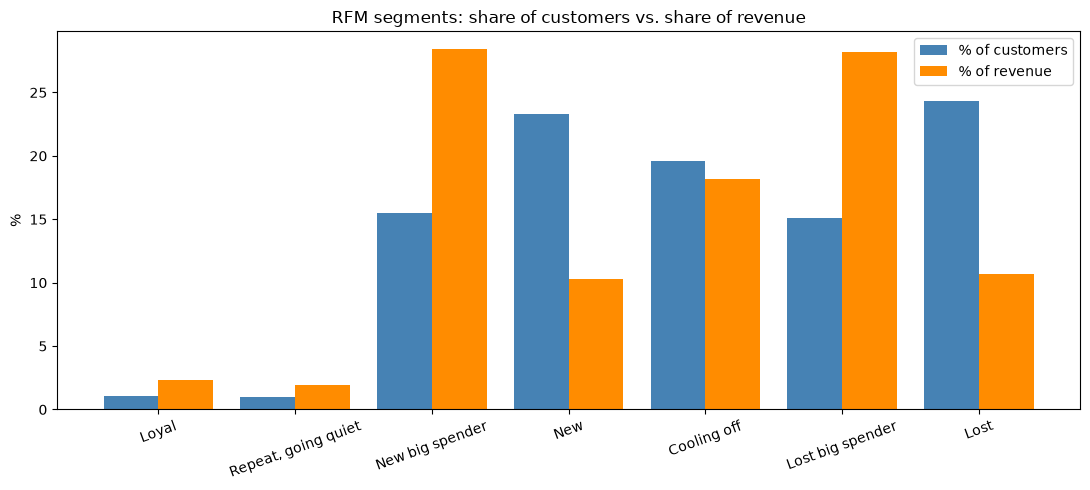

In [4]:
labels = segments["segment"].str[3:]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - 0.2, segments["pct_of_customers"], width=0.4, label="% of customers", color="steelblue")
ax.bar(x + 0.2, segments["pct_of_revenue"], width=0.4, label="% of revenue", color="darkorange")
ax.set_xticks(x, labels, rotation=20)
ax.set_ylabel("%")
ax.set_title("RFM segments: share of customers vs. share of revenue")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
pd.read_sql("""
SELECT
    f.category,
    COUNT(*) AS new_big_spenders,
    ROUND(AVG(r.monetary), 0) AS avg_spend
FROM customer_rfm r
JOIN first_orders f USING (customer_unique_id)
WHERE r.segment = '3. New big spender'
GROUP BY f.category
ORDER BY new_big_spenders DESC
LIMIT 8
""", engine)

,category,new_big_spenders,avg_spend
0,watches_gifts,1563,309.0
1,health_beauty,1520,318.0
2,bed_bath_table,1155,240.0
3,sports_leisure,1022,269.0
4,computers_accessories,1004,244.0
5,housewares,979,271.0
6,furniture_decor,920,253.0
7,auto,709,315.0


### Findings and actions
- **Only 2.1% of customers have ever bought twice** (Loyal + Repeat, going quiet), bringing 4.2% of revenue.
- **New big spenders are the opportunity: 15.5% of customers and 28.4% of revenue.** They bought recently,
  spent about R\$300, and most rated their order well. They are the best target for a second-order
  campaign, especially in watches & gifts, health & beauty, and bed/bath/table.
- **Lost big spenders hold another 28.2% of revenue,** but their last order was about 445 days ago. Winning
  them back will cost more than keeping the new ones.
- **Cooling off customers (19.6%) have the lowest average review (3.97),** consistent with notebook 04:
  more of them had a bad experience. A service-recovery message fits them better than a discount.

| Segment | Action |
|---|---|
| Loyal / Repeat, going quiet | Thank-you perks; ask for reviews and referrals |
| New big spender | Second-order offer 2-3 months after the first purchase, in the same category |
| New | Low-cost welcome series; cross-sell replenishable home categories |
| Cooling off | Service recovery if the first order was late or poorly rated, then an offer |
| Lost / Lost big spender | One low-cost win-back attempt, then stop spending on them |